# CNN-LSTM Image Classification

**Author:** Albert Kabore

**Affiliation:** PhD student, University of the Cumberlands

**Dataset:** Natural Images, eight classes

| Section | Topic |
| --- | --- |
| 1 | Introduction |
| 2 | Computational Environment |
| 3 | Dataset |
| 4 | Data Quality |
| 5 | Exploratory Data Analysis |
| 6 | Image Preprocessing |
| 7 | Model Architecture |
| 8 | Model Training |
| 9 | Test Set Performance |
| 10 | Hyperparameter Tuning |
| 11 | Final Insights and Recommendations |
| 12 | Conclusion |

## 1. Introduction

Convolutional neural networks (CNNs) extract image features using filters shared across spatial locations. Long Short-Term Memory (LSTM) networks process ordered inputs through recurrent states and gated memory.

In this study, each row of a CNN feature map forms one sequence step. A bidirectional LSTM processes the rows in both directions, preserving row order when forming the classification features.

The study compares CNN-LSTM models with pixel LSTM and CNN baselines, evaluates classification errors, and examines the effects of architecture and training settings.

### Experimental Design

- The project classifies photographs into eight Natural Images categories using a CNN feature extractor followed by an LSTM over rows.
- Reading feature rows as a sequence provides a testable hypothesis about spatial information; performance must be compared against classification models.
- The comparisons include a pixel LSTM, a CNN, and models with unidirectional or bidirectional recurrence, all using the same split.
- Validation macro F1 ranks configurations, while validation loss selects the checkpoint per run. Test metrics describe the selected model's performance.
- Results come from one seed and unequal model sizes, so the comparisons cannot establish that recurrence alone explains any improvement.

## 2. Computational Environment

In [1]:
RUN_TRAINING = False

import hashlib
import json
import platform
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "cnn_lstm").exists():  # notebook opened from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, PercentFormatter
TRAIN_COLOR = "#0072B2"
VALIDATION_COLOR = "#D55E00"
TEST_COLOR = "#009E73"
ARCHITECTURE_COLORS = {"pixel_lstm": "#CC79A7", "cnn_only": TEST_COLOR,
                       "cnn_lstm": VALIDATION_COLOR, "cnn_bilstm": TRAIN_COLOR}
REPORT_HEATMAP = LinearSegmentedColormap.from_list("report_blue", ["#F1F7FD", "#6BAED6", "#08519C"])

from cnn_lstm import data as D
from cnn_lstm import experiments as E
from cnn_lstm.metrics import compute_metrics
from cnn_lstm.models import build_model, count_parameters, describe
from cnn_lstm.train import predict, set_seed

torch.set_num_threads(8)
set_seed(42)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | "
      f"CUDA available: {torch.cuda.is_available()} | CPU threads: {torch.get_num_threads()}")
plt.rcParams.update({"text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black", "xtick.color": "black", "ytick.color": "black"})

Python 3.11.0 | PyTorch 2.14.0+cpu | CUDA available: False | CPU threads: 8


### Computing Resources

- The environment uses Python 3.11.0 and PyTorch 2.14.0 with a CPU build, eight processing threads, and no available CUDA device.
- All ten experiments shared the same input dimensions, image split and normalization statistics, supporting comparison under consistent data preparation conditions.
- Seed 42 controls the data split and random operations. Results can still differ when software versions, hardware, or settings change.
- Saved results cover ten experiments. Their recorded elapsed durations total 26.15 hours, including long intervals whose causes were not diagnosed.
- The selected run records 25.37 minutes. Elapsed durations do not establish active computation time or predict runtime on another machine.

## 3. Dataset

Natural Images contains 6,899 RGB photographs across eight object classes.

In [2]:
DATASET_DIR = ROOT / "data" / "natural-images"
if not E.DATA_ROOT.exists():
    import kagglehub
    kagglehub.dataset_download("prasunroy/natural-images", output_dir=str(DATASET_DIR))

all_files = [p for p in DATASET_DIR.rglob("*") if p.is_file()]
local_manifest = {p.relative_to(DATASET_DIR).as_posix(): p.stat().st_size for p in all_files}
published_manifest = json.loads((ROOT / "reports/audit_evidence/publisher_manifest.json").read_text())
verification = json.loads((ROOT / "reports/audit_evidence/publisher_verification.json").read_text())
assert local_manifest == published_manifest, "Current files differ from the saved publisher manifest"
print(f"files: {len(all_files):,} | bytes: {sum(local_manifest.values()):,}")
print(f"All names and sizes match the publisher manifest fetched {verification['checked_at_utc']}.")
print("The publisher manifest supplies no cryptographic content hashes.")
top = pd.Series([p.relative_to(DATASET_DIR).parts[0] for p in all_files]).value_counts()
top.rename("files").to_frame()

files: 13,798 | bytes: 359,403,192
All names and sizes match the publisher manifest fetched 2026-11-11T15:09:50.533374+00:00.
The publisher manifest supplies no cryptographic content hashes.


,files
data,6899
natural_images,6899


In [3]:
# The archive stores the dataset twice. Confirm the two copies are byte-identical before reading only one.
copy_a = {p.relative_to(DATASET_DIR / "natural_images").as_posix(): p for p in (DATASET_DIR / "natural_images").rglob("*.jpg")}
copy_b = {p.relative_to(DATASET_DIR / "data" / "natural_images").as_posix(): p
          for p in (DATASET_DIR / "data" / "natural_images").rglob("*.jpg")}
same_names = copy_a.keys() == copy_b.keys()
identical = sum(copy_a[k].read_bytes() == copy_b[k].read_bytes() for k in copy_a) if same_names else 0
print(f"copy 1: {len(copy_a):,} images | copy 2: {len(copy_b):,} images | same file names: {same_names} | "
      f"byte-identical pairs: {identical:,}")

copy 1: 6,899 images | copy 2: 6,899 images | same file names: True | byte-identical pairs: 6,899


### Dataset Structure

- The archive contains 13,798 files totalling 359,403,192 bytes. These totals include two folders containing the same set of 6,899 photographs.
- All filenames match between the folders, and direct byte comparisons confirm that every image pair contains the same bytes.
- The pipeline reads only the natural_images folder. Reading both copies before splitting could place identical images in training and test.
- The publisher audit reports matching filenames and file sizes. Publisher hashes were unavailable, so that comparison does not verify content cryptographically.
- Dataset files remain unchanged. Cleaning affects the index used for analysis, while photographs remain available for inspection and subsequent verification.

## 4. Data Quality

Images were examined for decoding failures, inconsistent formats, exact duplicates and perceptual similarity.

In [4]:
records = []
for cls_dir in sorted(p for p in E.DATA_ROOT.iterdir() if p.is_dir()):
    for p in sorted(cls_dir.iterdir()):
        rec = {"class": cls_dir.name, "file": p.name, "ext": p.suffix.lower(), "bytes": p.stat().st_size}
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                im.load()
                rec.update(format=im.format, mode=im.mode, width=im.size[0], height=im.size[1], readable=True)
        except Exception as exc:  # noqa: BLE001 - record any decode failure
            rec.update(readable=False, error=repr(exc))
        rec["sha1"] = hashlib.sha1(p.read_bytes()).hexdigest()
        records.append(rec)
audit = pd.DataFrame(records)

print(f"images audited: {len(audit):,}")
print(f"unreadable / corrupt: {(~audit['readable']).sum()}")
print(f"zero-byte files: {(audit['bytes'] == 0).sum()}")
print("extensions:", audit["ext"].value_counts().to_dict())
print("formats:", audit["format"].value_counts().to_dict())
print("colour modes:", audit["mode"].value_counts().to_dict())
small = audit[(audit["width"] < 64) | (audit["height"] < 64)]
print(f"images smaller than 64 px on a side (upscaled by the resize): {len(small)}")
aspect = audit["width"] / audit["height"]
print(f"aspect ratio (w/h) range: {aspect.min():.2f} to {aspect.max():.2f}; "
      f"outside 0.5-2.0: {((aspect < 0.5) | (aspect > 2.0)).sum()}")

images audited: 6,899
unreadable / corrupt: 0
zero-byte files: 0
extensions: {'.jpg': 6899}
formats: {'JPEG': 6898, 'PNG': 1}
colour modes: {'RGB': 6899}
images smaller than 64 px on a side (upscaled by the resize): 38
aspect ratio (w/h) range: 0.20 to 5.89; outside 0.5-2.0: 920


In [5]:
dupes = audit[audit.duplicated("sha1", keep=False)].sort_values(["sha1", "class", "file"])
groups = dupes.groupby("sha1")
cross_class = sum(g["class"].nunique() > 1 for _, g in groups)
print(f"exact-duplicate groups: {groups.ngroups} | files involved: {len(dupes)} | groups spanning classes: {cross_class}")
dupes[["class", "file", "bytes", "width", "height", "sha1"]]

exact-duplicate groups: 2 | files involved: 4 | groups spanning classes: 0


,class,file,bytes,width,height,sha1
3682,flower,flower_0400.jpg,21496,212,182,080513f8b0352ce5074a5ed6a55bd37c0544ac1b
4054,flower,flower_0772.jpg,21496,212,182,080513f8b0352ce5074a5ed6a55bd37c0544ac1b
963,car,car_0236.jpg,9487,100,100,20a00702f02a5e45f5ff77b218ce4834e6cb9271
1402,car,car_0675.jpg,9487,100,100,20a00702f02a5e45f5ff77b218ce4834e6cb9271


In [6]:
# Near-duplicate check: 64-bit average hash of the grayscale 8x8 thumbnail.
def average_hash(path):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((8, 8), Image.Resampling.BILINEAR), dtype=np.float32)
    return np.packbits((g > g.mean()).ravel()).tobytes()

audit["ahash"] = [average_hash(E.DATA_ROOT / c / f) for c, f in zip(audit["class"], audit["file"])]
hash_groups = audit.groupby("ahash")
near = audit[audit.duplicated("ahash", keep=False) & ~audit.duplicated("sha1", keep=False)]
print(f"images sharing an identical average hash with another, non-identical image: {len(near)}")
print("by class:", near["class"].value_counts().to_dict())

images sharing an identical average hash with another, non-identical image: 276
by class: {'fruit': 257, 'motorbike': 15, 'car': 2, 'airplane': 2}


### Data Cleaning Decisions

| Finding | Treatment |
| --- | --- |
| Duplicate archive copy | Use one copy of the dataset |
| Byte-identical image pairs | Retain one image per pair |
| Variable image dimensions | Resize RGB inputs to 64x64 pixels |
| Unreadable images | None identified |

In [7]:
index = D.index_dataset(E.DATA_ROOT)
print(f"images indexed for modelling: {len(index.paths):,} "
      f"(audited {len(audit):,} minus {index.duplicates_removed} duplicate copies)")

images indexed for modelling: 6,897 (audited 6,899 minus 2 duplicate copies)


### Image Quality

- All 6,899 photographs decode and use RGB color. None are empty; one file with a JPEG extension contains PNG data.
- Two pairs contain identical bytes within the car and flower classes. Indexing each pair once leaves 6,897 images for modelling.
- A total of 38 images have a side shorter than 64 pixels. Upscaling cannot recover detail absent from the originals.
- Aspect ratios range from 0.20 to 5.89, with 920 images outside 0.5 to 2.0. Square resizing changes their object proportions.
- Average hashes identify 276 candidates, including 257 fruit images. Hash matches indicate possible similarity and require visual checks before grouping.

## 5. Exploratory Data Analysis

In [8]:
eda = audit[audit["readable"]].groupby("class").agg(
    images=("file", "size"), median_w=("width", "median"), median_h=("height", "median"),
    min_w=("width", "min"), max_w=("width", "max"), min_h=("height", "min"), max_h=("height", "max"),
    median_kb=("bytes", lambda b: round(b.median() / 1024, 1)))
eda["share_%"] = (100 * eda["images"] / eda["images"].sum()).round(1)
print(f"largest / smallest class: {eda['images'].max() / eda['images'].min():.2f}x")
eda

largest / smallest class: 1.42x


,images,median_w,median_h,min_w,max_w,min_h,max_h,median_kb,share_%
class,,,,,,,,,
airplane,727,296.0,92.0,224,383,54,331,11.8,10.5
car,968,100.0,100.0,100,100,100,100,11.8,14.0
cat,885,315.0,309.0,59,499,73,499,34.9,12.8
dog,702,274.0,316.0,43,495,50,493,36.0,10.2
flower,843,365.0,319.0,51,2737,59,2665,56.9,12.2
fruit,1000,100.0,100.0,100,100,100,100,4.5,14.5
motorbike,788,193.0,108.5,124,213,66,151,13.2,11.4
person,986,256.0,256.0,250,256,250,256,16.0,14.3


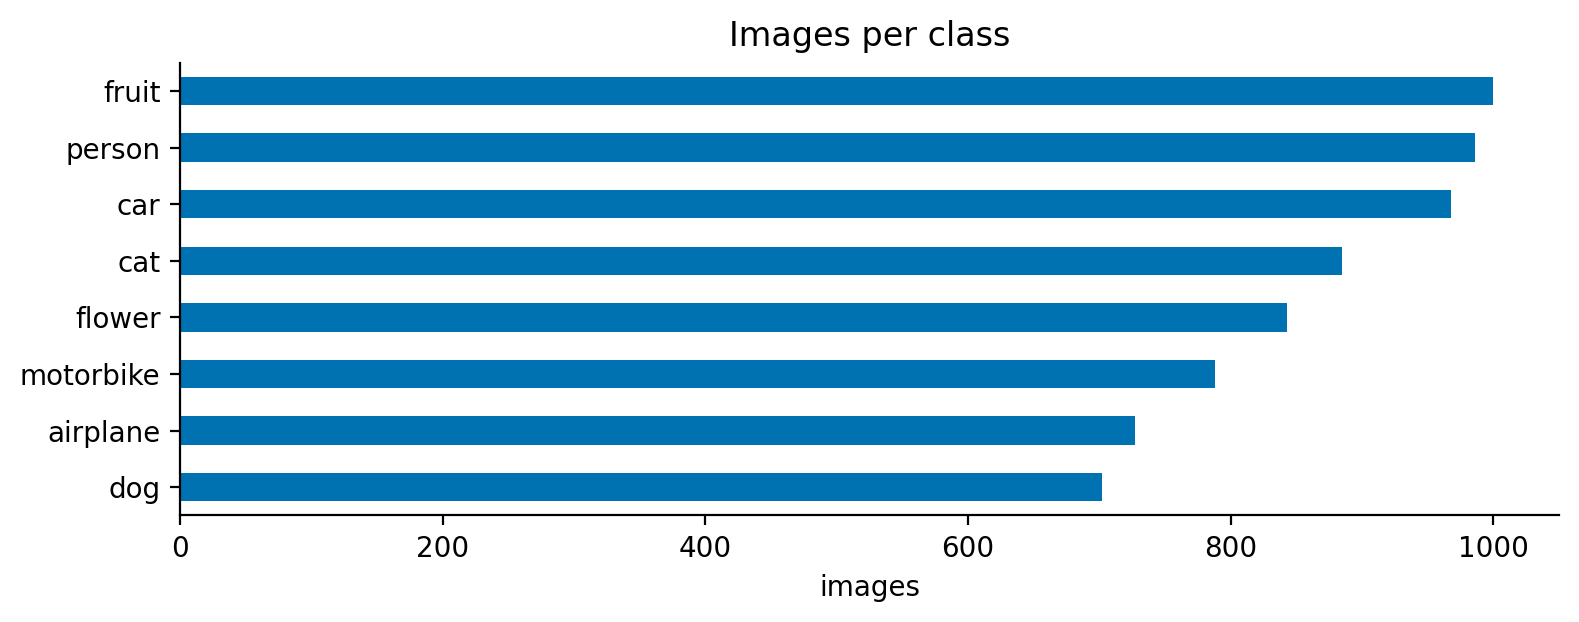

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
eda["images"].sort_values().plot.barh(ax=ax, color=TRAIN_COLOR)
ax.set_xlabel("images")
ax.set_title("Images per class")
plt.tight_layout()

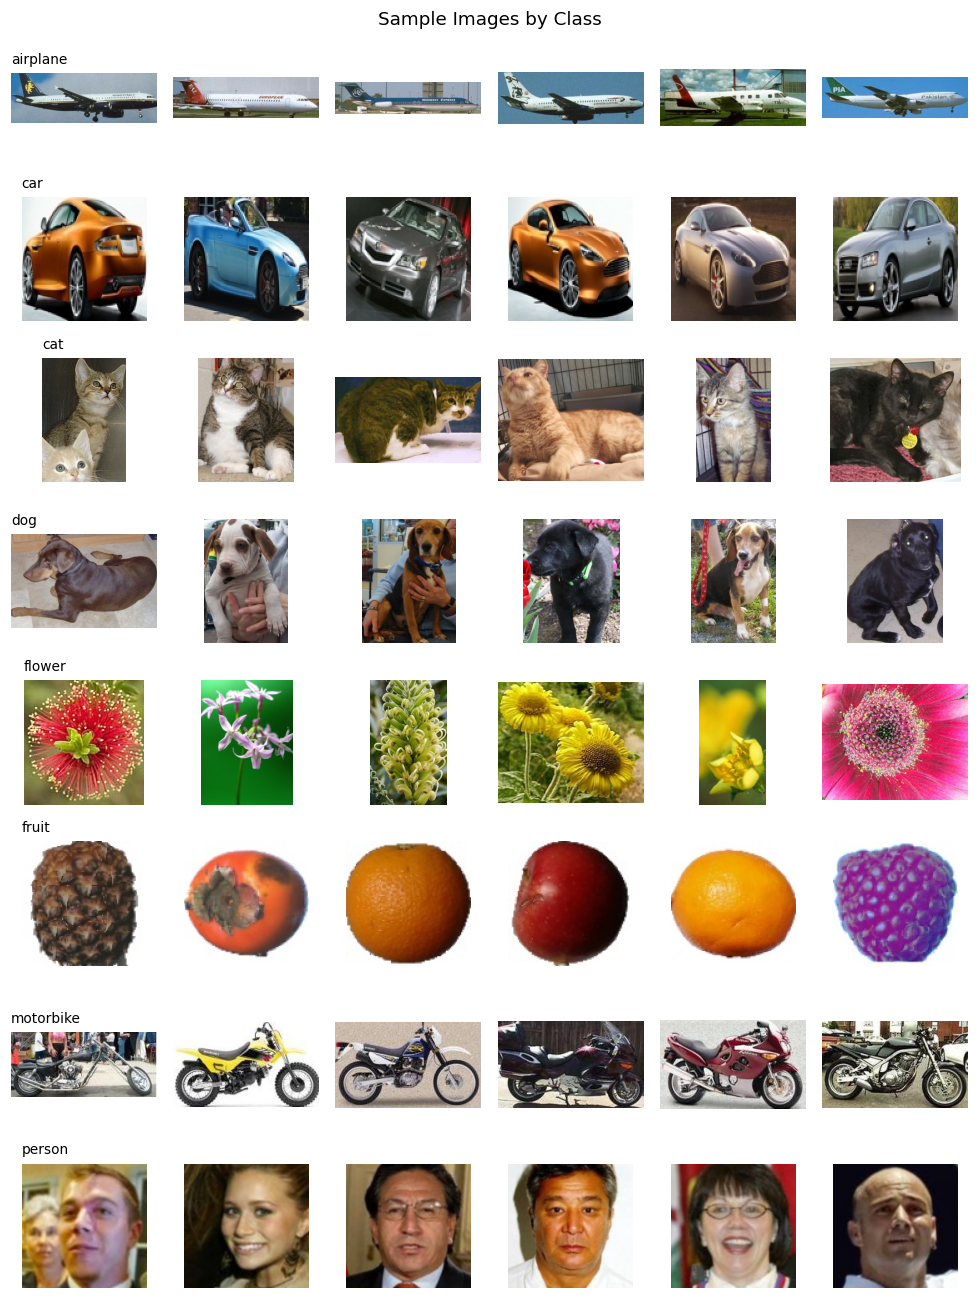

In [10]:
display_rules = json.loads((ROOT / "reports/display_exclusions.json").read_text())
display_replacements = display_rules["example_replacements"]
fig, axes = plt.subplots(len(index.classes), 6, figsize=(9, 12))
rng = np.random.default_rng(0)
for r, cls in enumerate(index.classes):
    for c, i in enumerate(rng.choice(np.flatnonzero(index.labels == r), 6, replace=False)):
        path = display_replacements.get(index.paths[i], index.paths[i])
        with Image.open(E.DATA_ROOT / path) as im:
            axes[r, c].imshow(im.convert("RGB"))
        axes[r, c].axis("off")
    axes[r, 0].set_title(cls, loc="left", fontsize=9)
fig.suptitle("Sample Images by Class")
plt.tight_layout()

In [11]:
# Mean colour per class on the 64x64 versions, a quick check for colour or background shortcuts.
images64 = D.load_or_build_cache(E.DATA_ROOT, index, E.IMAGE_SIZE, E.CACHE_DIR)
colour = pd.DataFrame([images64[index.labels == k].reshape(-1, 3).mean(0) / 255 for k in range(len(index.classes))],
                      index=index.classes, columns=["mean_R", "mean_G", "mean_B"])
colour["brightness"] = colour.mean(1)
colour.round(3)

,mean_R,mean_G,mean_B,brightness
airplane,0.452,0.494,0.501,0.482
car,0.420,0.407,0.397,0.408
cat,0.469,0.434,0.400,0.434
dog,0.488,0.450,0.409,0.449
flower,0.500,0.419,0.325,0.414
fruit,0.719,0.614,0.517,0.617
motorbike,0.503,0.485,0.475,0.487
person,0.500,0.410,0.349,0.420


### Class Distribution and Image Characteristics

- Fruit contains 1,000 photographs and dog contains 702, giving a largest to smallest class ratio of 1.42. Class frequencies are unequal.
- Macro F1 gives each class equal influence, making performance on smaller categories easier to identify than overall accuracy alone.
- Car and fruit images are 100x100 pixels. Resizing removes dimension differences, although compression and sampling patterns may be associated with labels.
- Fruit has mean brightness 0.617, compared with 0.408 to 0.487 elsewhere. This difference suggests a background or lighting shortcut.
- Airplane images have median dimensions of 296x92 pixels. Resizing them to 64x64 distorts proportions and warrants comparing padding before resizing.

## 6. Image Preprocessing

- Images were resized to 64x64 RGB using bicubic interpolation.
- Stratified training, validation and test splits used a 70/15/15 allocation and seed 42.
- Channel normalization used training-set means and standard deviations.
- When enabled, training augmentation included horizontal flips, reflection-padded shifts of up to six pixels, and brightness and contrast factors between 0.8 and 1.2.
- Validation and test images received deterministic resizing and normalization.

In [12]:
splits, norm, info = E.prepare_data(log=lambda _: None)
counts = pd.DataFrame(info["class_counts"], index=info["classes"])
counts.loc["total"] = counts.sum()
print("channel mean:", np.round(info["channel_mean"], 3), "| channel std:", np.round(info["channel_std"], 3))
counts

channel mean: [0.51  0.464 0.419] | channel std: [0.287 0.279 0.292]


,train,val,test
airplane,509,109,109
car,677,145,145
cat,619,133,133
dog,491,106,105
flower,589,126,127
fruit,700,150,150
motorbike,552,118,118
person,690,148,148
total,4827,1035,1035


In [13]:
# Screen for average-hash matches across the actual split assignments.
hash_of = dict(zip(audit["class"] + "/" + audit["file"], audit["ahash"]))
training_idx, validation_idx, test_idx = D.stratified_split(index.labels, .15, .15, 42)
training_hashes = {hash_of[index.paths[i]] for i in training_idx}
training_validation_hashes = training_hashes | {hash_of[index.paths[i]] for i in validation_idx}
test_with_twin = [p for p in info["test_paths"] if hash_of[p] in training_validation_hashes]
print("Test candidates matching training:", sum(hash_of[p] in training_hashes for p in info["test_paths"]))
print("Test candidates matching training or validation:", len(test_with_twin), "of", len(info["test_paths"]))
print("By class:", pd.Series([p.split('/')[0] for p in test_with_twin]).value_counts().to_dict())
print("A matching hash flags possible similarity; it does not prove duplication.")

Test candidates matching training: 39
Test candidates matching training or validation: 41 of 1035
By class: {'fruit': 38, 'motorbike': 3}
A matching hash flags possible similarity; it does not prove duplication.


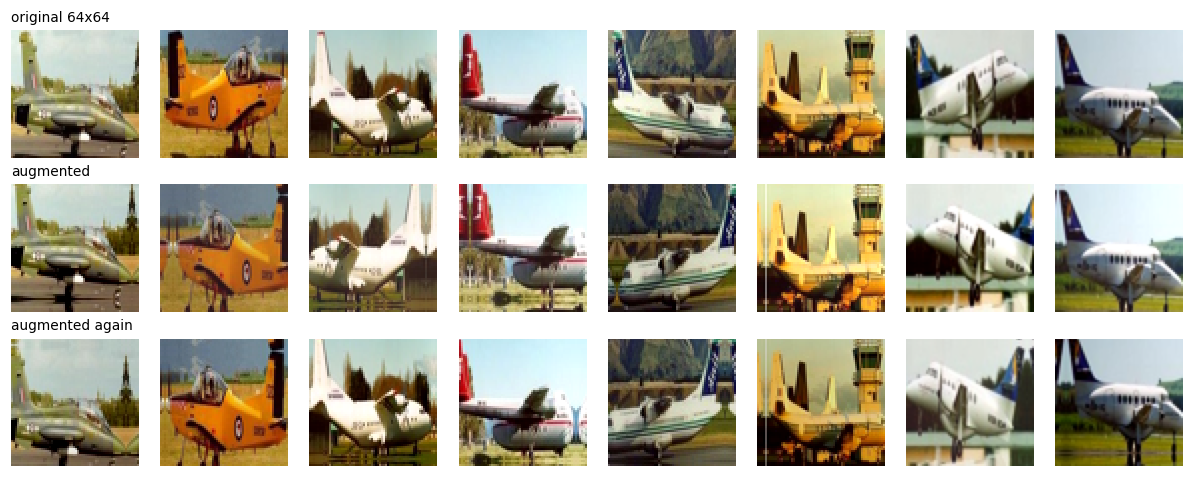

In [14]:
x = norm.to_unit(splits["train"].x[:8])
aug = D.Augmenter(seed=1)
fig, axes = plt.subplots(3, 8, figsize=(11, 4.4))
for r, batch in enumerate([x, aug(x), aug(x)]):
    for c in range(8):
        axes[r, c].imshow(batch[c].permute(1, 2, 0).numpy())
        axes[r, c].axis("off")
    axes[r, 0].set_title(["original 64x64", "augmented", "augmented again"][r], loc="left", fontsize=9)
plt.tight_layout()

### Data Split and Normalization

- Stratification assigns 4,827 to training, 1,035 to validation, and 1,035 to testing. Seed 42 fixes the split, preserving class proportions.
- Training images determine means of 0.510, 0.464, and 0.419, with standard deviations of 0.287, 0.279, and 0.292 for RGB.
- Inputs use 64x64 RGB arrays produced by bicubic resizing. Cached arrays match fresh conversions in the audit, supporting preprocessing consistency.
- 41 test images share identical average hashes with training or validation images: 38 fruit and three motorbikes. Their impact remains unmeasured.
- Augmentation applies only when enabled during training. Validation and test inputs receive resizing and normalization; the selected configuration disables augmentation.

## 7. Model Architecture

The CNN contains three blocks, each with two 3x3 convolutions, batch normalization, ReLU and 2x2 max pooling. The 64x64x3 input becomes an 8x8x128 feature map.

Each feature-map row supplies 1,024 values to a bidirectional LSTM with 128 hidden units per direction. The final forward and backward states form a 256-value vector, which a classification head maps to eight class scores.

The baseline uses spatial dropout of 0.1 and sequence/head dropout of 0.5. The selected configuration sets these probabilities to zero.

The pixel LSTM processes 64 rows of image pixels. The CNN baseline replaces recurrence with global average pooling.

In [15]:
main_model = build_model("cnn_lstm", 8, image_size=64, hidden=128, layers=1, bidirectional=True, dropout=0.5)
print(describe(main_model))

Layer                                Output shape        Params
-----------------------------------------------------------------
backbone.features.0.0 (Conv2d)       [2, 32, 64, 64]     864
backbone.features.0.1 (BatchNorm2d)  [2, 32, 64, 64]     64
backbone.features.0.2 (ReLU)         [2, 32, 64, 64]     0
backbone.features.0.3 (Conv2d)       [2, 32, 64, 64]     9,216
backbone.features.0.4 (BatchNorm2d)  [2, 32, 64, 64]     64
backbone.features.0.5 (ReLU)         [2, 32, 64, 64]     0
backbone.features.0.6 (MaxPool2d)    [2, 32, 32, 32]     0
backbone.features.0.7 (Dropout2d)    [2, 32, 32, 32]     0
backbone.features.1.0 (Conv2d)       [2, 64, 32, 32]     18,432
backbone.features.1.1 (BatchNorm2d)  [2, 64, 32, 32]     128
backbone.features.1.2 (ReLU)         [2, 64, 32, 32]     0
backbone.features.1.3 (Conv2d)       [2, 64, 32, 32]     36,864
backbone.features.1.4 (BatchNorm2d)  [2, 64, 32, 32]     128
backbone.features.1.5 (ReLU)         [2, 64, 32, 32]     0
backbone.features.1.6 

In [16]:
pd.DataFrame(
    [(e.name, e.group, e.description, count_parameters(build_model(e.arch, 8, image_size=64, **e.model)))
     for e in E.EXPERIMENTS],
    columns=["experiment", "group", "description", "parameters"],
).set_index("experiment")

,group,description,parameters
experiment,,,
pixel_lstm,architecture,"LSTM only, 64 rows of raw pixels",315016
cnn_only,architecture,"CNN + global average pooling, no LSTM",305128
cnn_lstm,architecture,CNN + unidirectional LSTM,895976
cnn_bilstm,architecture,CNN + bidirectional LSTM (baseline),1503208
tune_hidden256,tuning,LSTM hidden size 256,2979816
tune_layers2,tuning,Two stacked LSTM layers,1898472
tune_dropout03,tuning,Dropout 0.3,1503208
tune_lr3e4,tuning,Learning rate 3e-4,1503208
tune_no_aug,tuning,No data augmentation,1503208


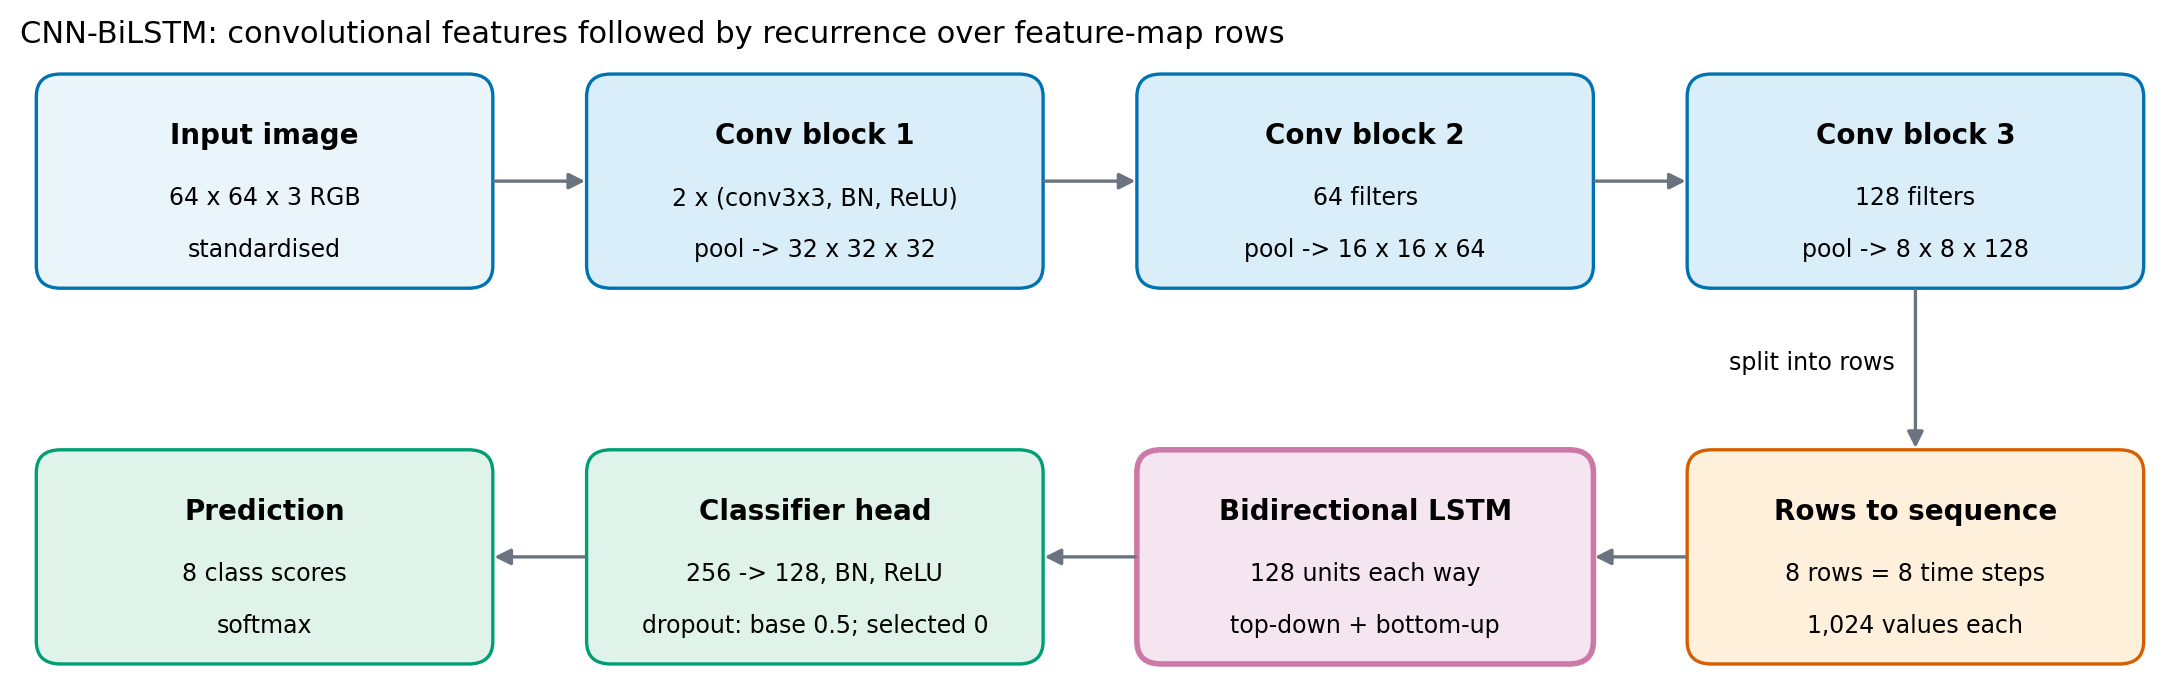

In [17]:
from IPython.display import Image as DisplayImage, display
display(DisplayImage(filename=str(ROOT / "results/figures/architecture_diagram.png")))

### Model Complexity

- The CNN with bidirectional LSTM contains 1,503,208 trainable parameters. Its recurrent layer contributes 1,181,696 parameters, approximately 79% of the total.
- The convolutional backbone contains 287,456 parameters and the classification head contains 34,056. Convolutions produce an 8x8 map with 128 channels.
- Each row supplies 1,024 values to the recurrent layer, yielding eight sequence steps and 128 hidden units in each direction.
- The pixel LSTM and CNN controls contain 315,016 and 305,128 parameters. Their capacity limits conclusions about recurrence from accuracy differences.
- Feature positions are eight pixels apart. Each final convolutional cell has a 36x36 receptive field before rows enter the LSTM.

## 8. Model Training

Training used AdamW, a one-cycle learning-rate schedule, batch size 64, gradient clipping at 1.0 and a 20-epoch limit. Baseline weight decay was 0.0001 and the peak learning rate was 0.001.

Validation loss determined checkpoint retention, with a six-epoch early-stopping patience. Validation macro F1 determined the configuration ranking. The selected configuration disabled augmentation, dropout and weight decay while retaining batch normalization.

Models were implemented in PyTorch, with classification metrics calculated using scikit-learn.

In [18]:
if RUN_TRAINING:
    E.main(["--rerun"])

summary = json.loads((E.RESULTS_DIR / "summary.json").read_text())
runs = {p.parent.name: json.loads(p.read_text()) for p in (E.RESULTS_DIR / "runs").glob("*/result.json")}
best_name = summary["selected"]
best = runs[best_name]
h = best["history"]
print(f"Selected model: {best_name}")
print(f"epochs run: {best['epochs_run']} | best epoch: {h['best_epoch']} | stopped early: {h['stopped_early']} | "
      f"recorded elapsed: {best['train_seconds'] / 60:.1f} min | mean epoch: {np.mean(h['epoch_seconds']):.1f} s")
print(f"at best epoch: train acc {h['train_acc'][h['best_epoch'] - 1]:.4f}, val acc {h['val_acc'][h['best_epoch'] - 1]:.4f}, "
      f"train loss {h['train_loss'][h['best_epoch'] - 1]:.4f}, val loss {h['val_loss'][h['best_epoch'] - 1]:.4f}")

Selected model: tune_no_reg
epochs run: 20 | best epoch: 17 | stopped early: False | recorded elapsed: 25.4 min | mean epoch: 76.1 s
at best epoch: train acc 1.0000, val acc 0.9517, train loss 0.0012, val loss 0.1632


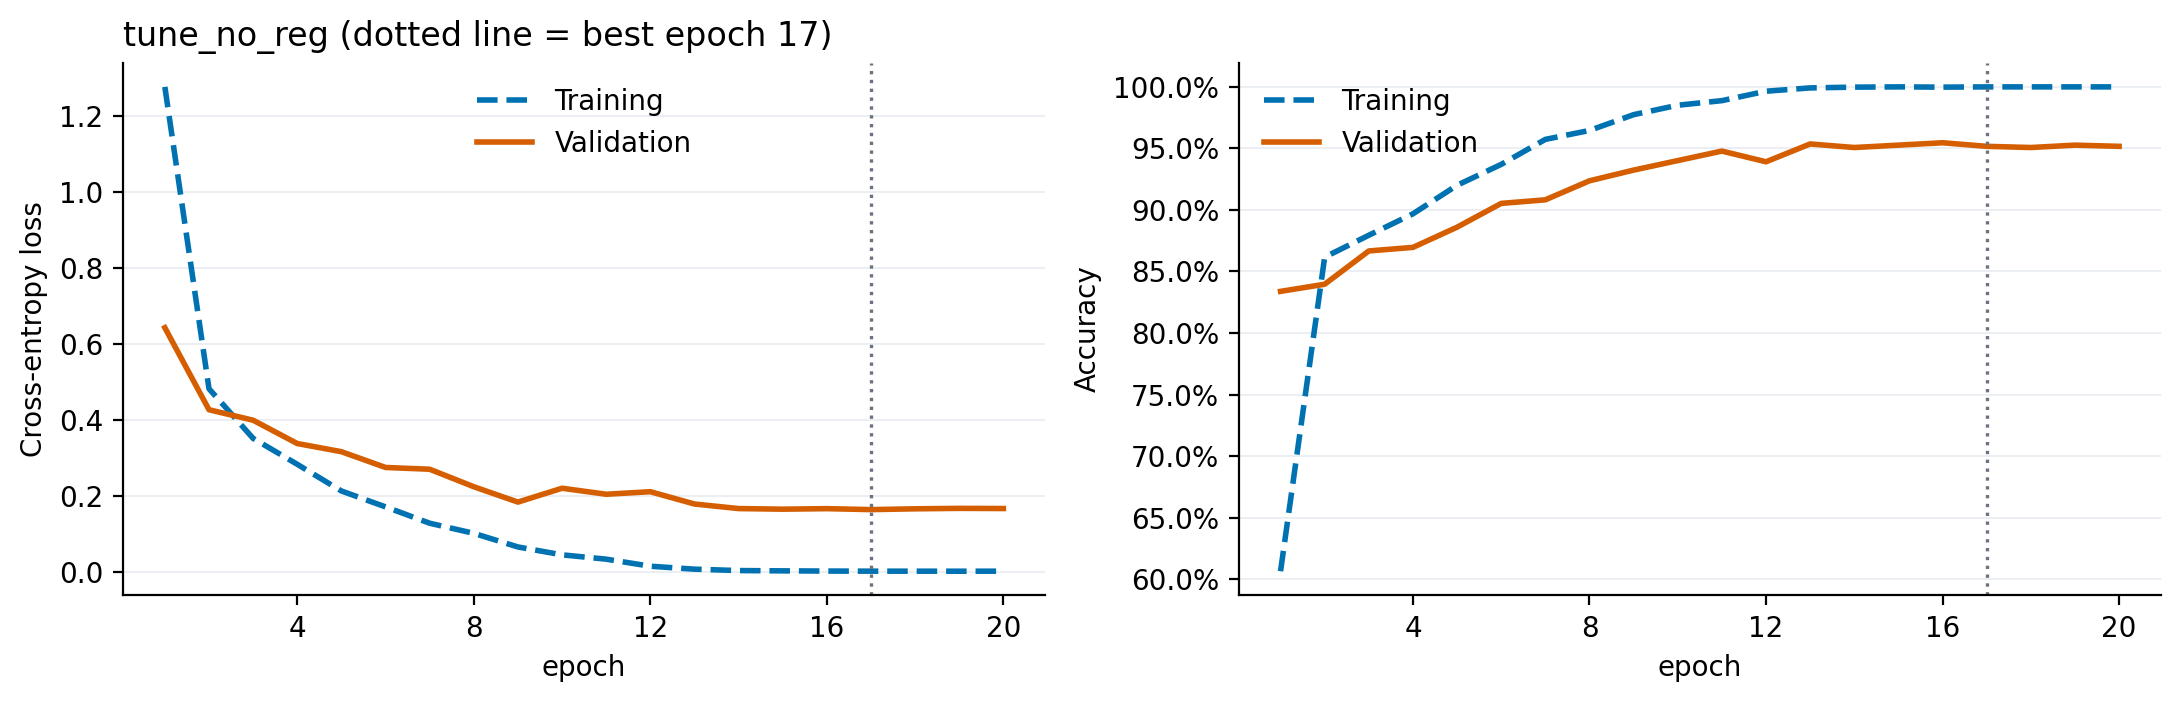

In [19]:
def plot_history(run, ax_loss, ax_acc):
    hh = run["history"]
    ep = range(1, len(hh["train_loss"]) + 1)
    for ax, key in ((ax_loss, "loss"), (ax_acc, "acc")):
        ax.plot(ep, hh[f"train_{key}"], color=TRAIN_COLOR, ls="--", lw=2, label="Training")
        ax.plot(ep, hh[f"val_{key}"], color=VALIDATION_COLOR, lw=2, label="Validation")
        ax.axvline(hh["best_epoch"], color="#6B7280", ls=":", lw=1.2)
        ax.set_xlabel("epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.set_ylabel("Cross-entropy loss" if key == "loss" else "Accuracy")
        ax.grid(axis="y", color="#CBD5E1", alpha=0.45, linewidth=0.6)
        if key == "acc":
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.legend(frameon=False)
    ax_loss.set_title(f"{run['name']} (dotted line = best epoch {hh['best_epoch']})", loc="left")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_history(best, *axes)
plt.tight_layout()

### Training Results

- Ten experiments ran for 20 epochs. The selected configuration retained epoch 17, when its validation loss reached the minimum.
- The selected run disabled augmentation, dropout, and weight decay while retaining batch normalization, gradient clipping, and the checkpoint selection rule.
- At the retained epoch, training accuracy was 100% and validation accuracy was 95.17%. This difference warrants evaluation on independent images.
- Training loss was 0.00118 and validation loss was 0.16317. Training and evaluation settings differ, which affects comparisons between these values.
- Runs are ranked by validation macro F1. Test scores are logged per experiment; evaluation was not deferred until all experiments finished.

## 9. Test Set Performance

Performance was evaluated on 1,035 test images using accuracy, precision, recall and F1. The confusion matrix and class-level metrics were used to examine classification errors.

In [20]:
meta = json.loads((E.CKPT_DIR / "best_model.json").read_text())
model = build_model(meta["arch"], len(info["classes"]), image_size=E.IMAGE_SIZE, **meta["model"])
model.load_state_dict(torch.load(E.CKPT_DIR / "best_model.pt", map_location="cpu", weights_only=True))
probs = predict(model, splits["test"].x, norm)
saved_probabilities = np.load(E.RESULTS_DIR / "runs" / meta["name"] / "test_probs.npy")
np.testing.assert_array_equal(probs, saved_probabilities)
m = compute_metrics(splits["test"].y, probs, info["classes"])
print(f"checkpoint: {meta['name']} ({meta['params']:,} parameters)")
pd.Series({k: m[k] for k in ("accuracy", "top2_accuracy", "macro_precision", "macro_recall", "macro_f1",
                             "weighted_precision", "weighted_recall", "weighted_f1")}, name="test").to_frame()

checkpoint: tune_no_reg (1,503,208 parameters)


,test
accuracy,0.9633
top2_accuracy,0.9942
macro_precision,0.9604
macro_recall,0.9601
macro_f1,0.9602
weighted_precision,0.9635
weighted_recall,0.9633
weighted_f1,0.9634


In [21]:
per_class = pd.DataFrame(m["per_class"]).T
per_class["support"] = per_class["support"].astype(int)
per_class.sort_values("f1")

,precision,recall,f1,support
dog,0.8462,0.8381,0.8421,105
cat,0.8750,0.8947,0.8848,133
flower,0.9843,0.9843,0.9843,127
car,1.0000,0.9793,0.9895,145
airplane,0.9908,0.9908,0.9908,109
person,0.9932,0.9932,0.9932,148
fruit,0.9934,1.0000,0.9967,150
motorbike,1.0000,1.0000,1.0000,118


,true,predicted,count
0,dog,cat,15
1,cat,dog,12
2,car,dog,2
3,dog,flower,2
4,flower,dog,2
5,airplane,fruit,1
6,car,cat,1
7,cat,airplane,1


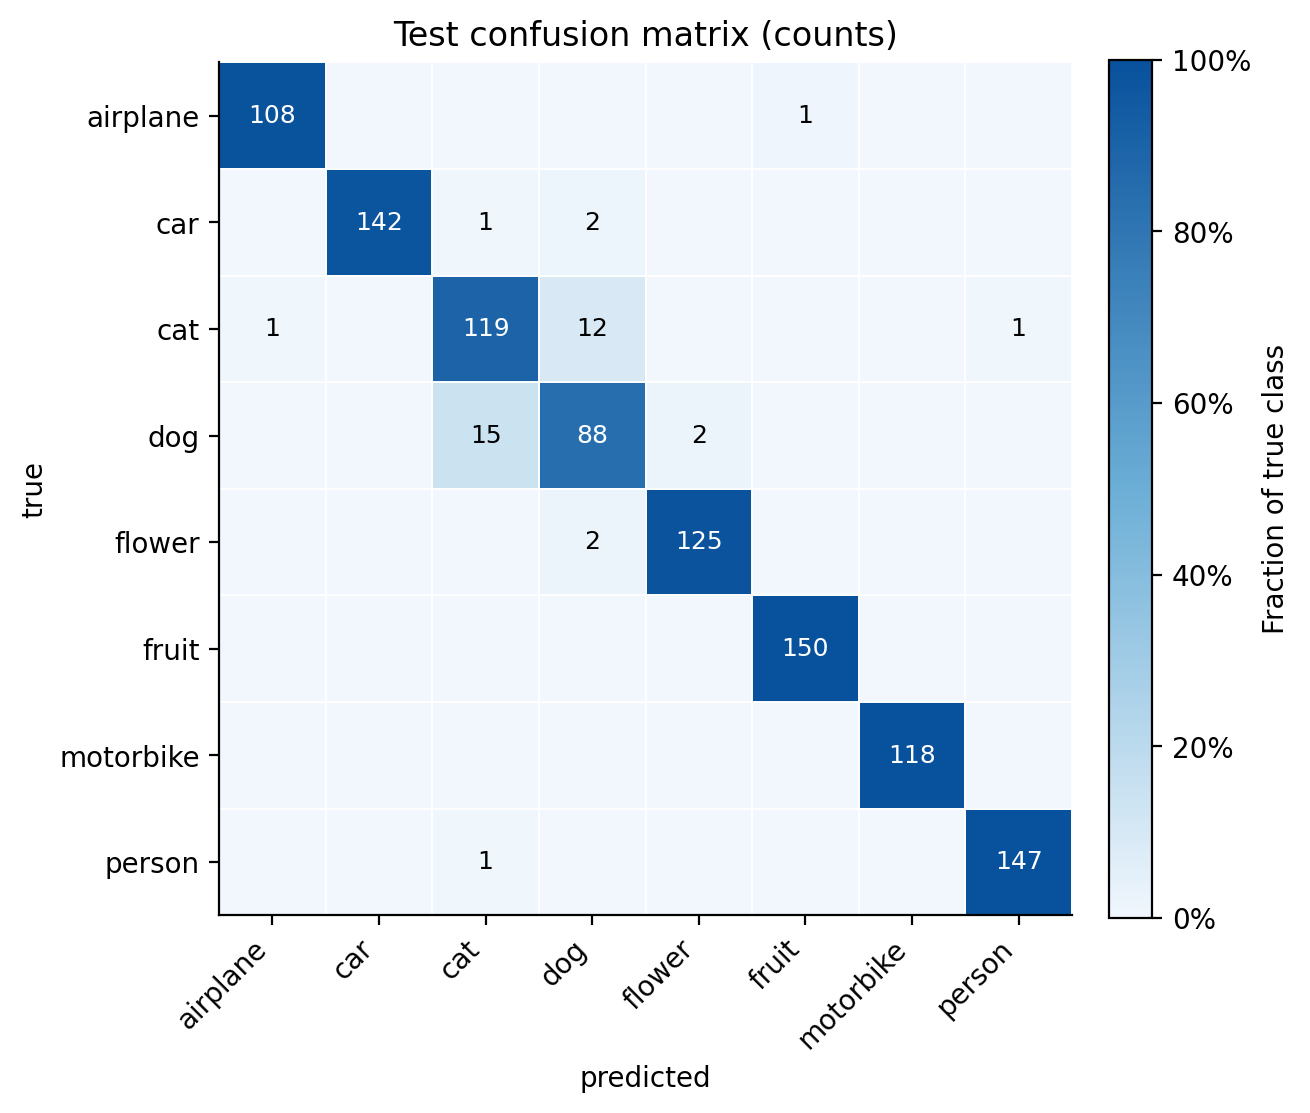

In [22]:
cm = np.array(m["confusion_matrix"])
share = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.8))
image = ax.imshow(share, cmap=REPORT_HEATMAP, vmin=0, vmax=1)
for i in range(len(cm)):
    for j in range(len(cm)):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if share[i, j] > 0.55 else "black")
ax.set_xticks(range(len(cm)), info["classes"], rotation=45, ha="right")
ax.set_yticks(range(len(cm)), info["classes"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Test confusion matrix (counts)")
ax.set_xticks(np.arange(len(cm) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(cm) + 1) - 0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=0.7)
ax.tick_params(which="minor", bottom=False, left=False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Fraction of true class")
colorbar.ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()

off = [(info["classes"][i], info["classes"][j], int(cm[i, j])) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j]]
pd.DataFrame(sorted(off, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])

38 of 1035 test images misclassified


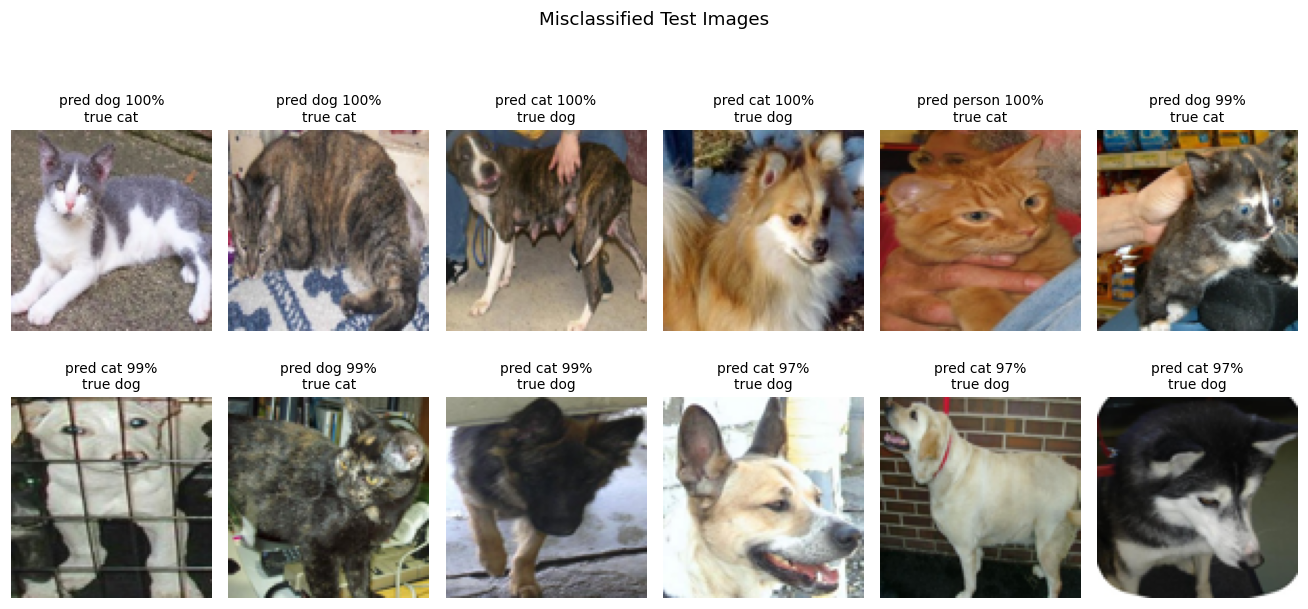

In [23]:
pred = probs.argmax(1)
wrong = np.flatnonzero(pred != splits["test"].y)
print(f"{len(wrong)} of {len(pred)} test images misclassified")
excluded_displays = set(display_rules["excluded_paths"])
eligible = [i for i in wrong if info["test_paths"][i] not in excluded_displays]
show = sorted(eligible, key=lambda i: -float(probs[i].max()))[:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 6))
for ax, i in zip(axes.flat, show):
    ax.imshow(D.load_image(E.DATA_ROOT / info["test_paths"][i], 96))
    ax.set_title(f"pred {info['classes'][pred[i]]} {probs[i].max():.0%}\ntrue {info['classes'][splits['test'].y[i]]}",
                 fontsize=9, color="black")
    ax.axis("off")
fig.suptitle("Misclassified Test Images")
plt.tight_layout(rect=(0, 0, 1, .94), h_pad=2.0)

### Confidence Intervals and Sensitivity Analysis

Accuracy intervals use the Wilson method. Macro F1 intervals use 2,000 bootstrap resamples within true classes, with replacement, seed 42 and fixed class counts. Paired model comparisons use the same sampled images.

These intervals condition on the fitted models and assume independent images. They exclude retraining, seed, selection and distribution-shift uncertainty. Related images may violate independence.

Scores after excluding average-hash candidates describe a post hoc subset of the original test set; they do not establish an independent holdout.

In [24]:
from reports.analyse_results import analyse
additional = analyse()
intervals = pd.DataFrame([
    ["Test accuracy", additional["accuracy"], *additional["accuracy_wilson_95"]],
    ["Test macro F1", additional["macro_f1"], *additional["macro_f1_bootstrap_95"]],
    ["Selected minus baseline accuracy", additional["selected_minus_baseline_accuracy"],
     *additional["paired_accuracy_improvement_bootstrap_95"]],
], columns=["estimate", "value", "lower_95", "upper_95"])
display(intervals.set_index("estimate"))
display(pd.DataFrame(additional["sensitivity"]).T)
print("Paired contrast: corrected baseline errors:", additional["selected_correct_baseline_wrong"],
      "| introduced errors:", additional["selected_wrong_baseline_correct"])

,value,lower_95,upper_95
estimate,,,
Test accuracy,0.9633,0.9500,0.9731
Test macro F1,0.9602,0.9481,0.9718
Selected minus baseline accuracy,0.0415,0.0261,0.0570


,images,correct,accuracy,macro_f1
hash_match_candidates,41.0,41.0,1.0000,NaN
remaining_test_images,994.0,956.0,0.9618,0.96


Paired contrast: corrected baseline errors: 58 | introduced errors: 15


### Classification Results

- The model correctly classified 997 of 1,035 test images, producing 96.33% accuracy and macro F1 of 0.9602 on this split.
- Macro precision was 96.04% and macro recall was 96.01%. The checkpoint audit reproduced the test probabilities, with no changed predictions.
- Dogs had F1 of 0.8421 and cats had 0.8848. Confusion between these classes accounted for 27 of the 38 errors.
- 118 motorbike images were classified correctly. Fruit recall was 100%, although similar images across splits limit interpretation of those scores.
- Measurements describe one split and seed. Similarity between images across splits limits conclusions about reported classification performance on independent photographs.

## 10. Hyperparameter Tuning

Four architectures were compared using the same split and seed. Five tuning runs separately changed hidden size, recurrent depth, dropout, learning rate or augmentation. A sixth run disabled augmentation, dropout and weight decay jointly.

The combined ablation does not isolate the effect of each setting. Configuration selection used validation macro F1.

In [25]:
table = pd.DataFrame(summary["runs"]).set_index("name")
table["train_val_gap"] = table["final_train_acc"] - table["val_acc"]
table[["group", "description", "params", "best_epoch", "train_minutes", "final_train_acc", "val_acc",
       "train_val_gap", "val_macro_f1", "test_acc", "test_macro_f1"]]

,group,description,params,best_epoch,train_minutes,final_train_acc,val_acc,train_val_gap,val_macro_f1,test_acc,test_macro_f1
name,,,,,,,,,,,
tune_no_reg,tuning,"No augmentation, dropout or weight decay",1503208,17,25.37,1.0000,0.9517,0.0483,0.9471,0.9633,0.9602
tune_no_aug,tuning,No data augmentation,1503208,20,946.65,0.9447,0.9401,0.0046,0.9342,0.9440,0.9397
tune_dropout03,tuning,Dropout 0.3,1503208,20,95.01,0.9109,0.9382,-0.0272,0.9314,0.9411,0.9360
tune_hidden256,tuning,LSTM hidden size 256,2979816,20,25.35,0.9076,0.9295,-0.0219,0.9217,0.9382,0.9322
tune_layers2,tuning,Two stacked LSTM layers,1898472,20,36.29,0.8977,0.9266,-0.0289,0.9190,0.9353,0.9296
cnn_bilstm,architecture,CNN + bidirectional LSTM (baseline),1503208,20,25.26,0.8805,0.9150,-0.0345,0.9040,0.9217,0.9126
cnn_lstm,architecture,CNN + unidirectional LSTM,895976,20,22.45,0.8651,0.8986,-0.0334,0.8754,0.8986,0.8755
tune_lr3e4,tuning,Learning rate 3e-4,1503208,20,366.62,0.8484,0.8802,-0.0318,0.8618,0.8889,0.8709
cnn_only,architecture,"CNN + global average pooling, no LSTM",305128,20,22.20,0.8307,0.8899,-0.0591,0.8582,0.8763,0.8448


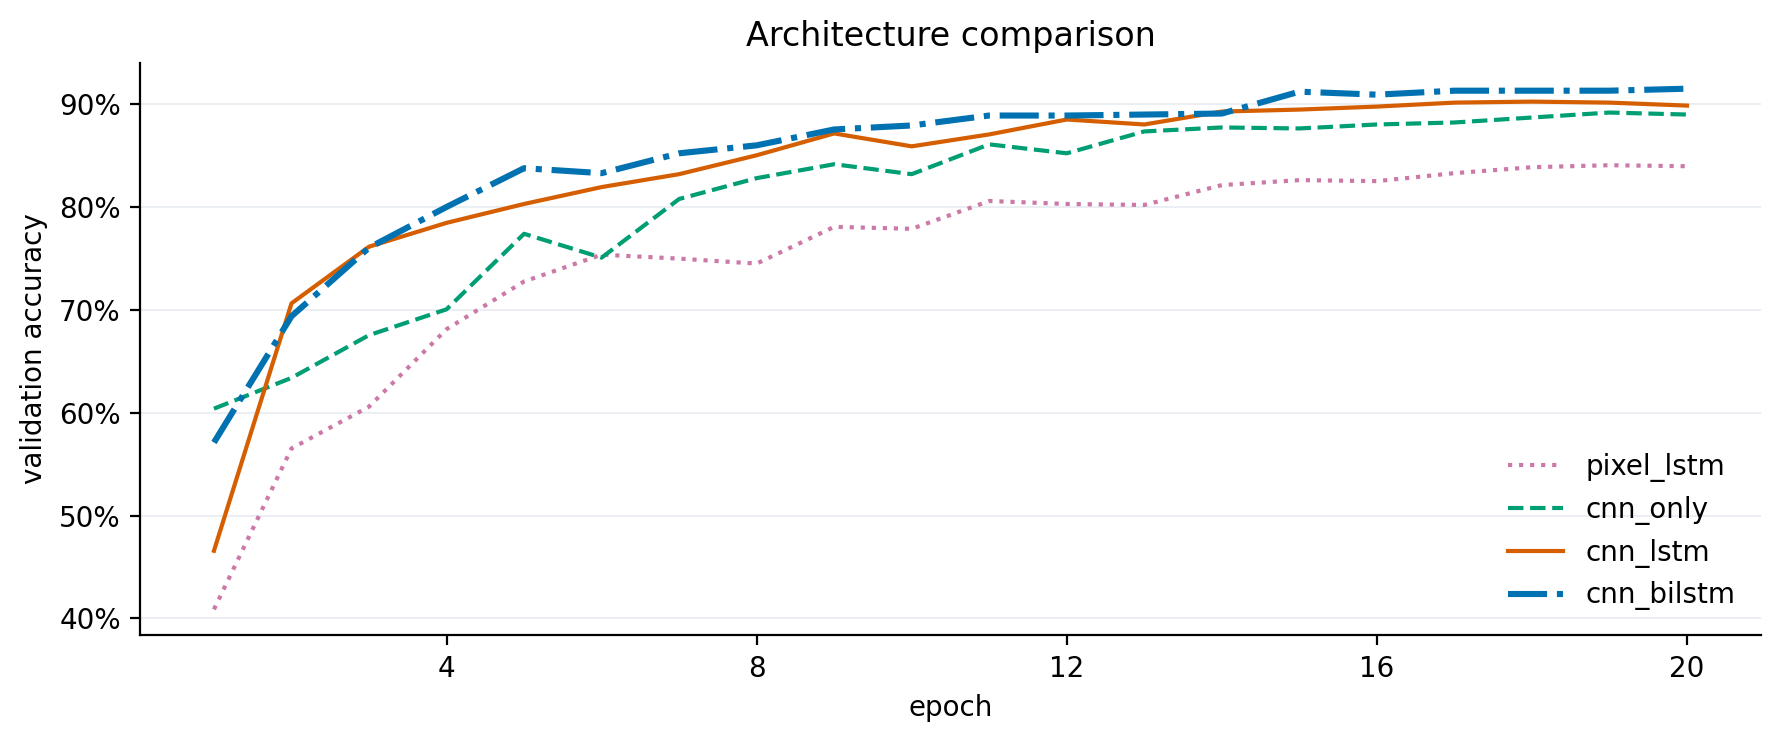

In [26]:
fig, ax = plt.subplots(figsize=(9, 3.8))
line_styles = {"pixel_lstm": ":", "cnn_only": "--", "cnn_lstm": "-", "cnn_bilstm": "-."}
for name in ("pixel_lstm", "cnn_only", "cnn_lstm", "cnn_bilstm"):
    v = runs[name]["history"]["val_acc"]
    ax.plot(range(1, len(v) + 1), v, label=name, color=ARCHITECTURE_COLORS[name], ls=line_styles[name], lw=2.2 if name == "cnn_bilstm" else 1.5)
ax.set_xlabel("epoch")
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
ax.set_ylabel("validation accuracy")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", color="#CBD5E1", alpha=0.45, linewidth=0.6)
ax.set_title("Architecture comparison")
ax.legend(frameon=False)
plt.tight_layout()

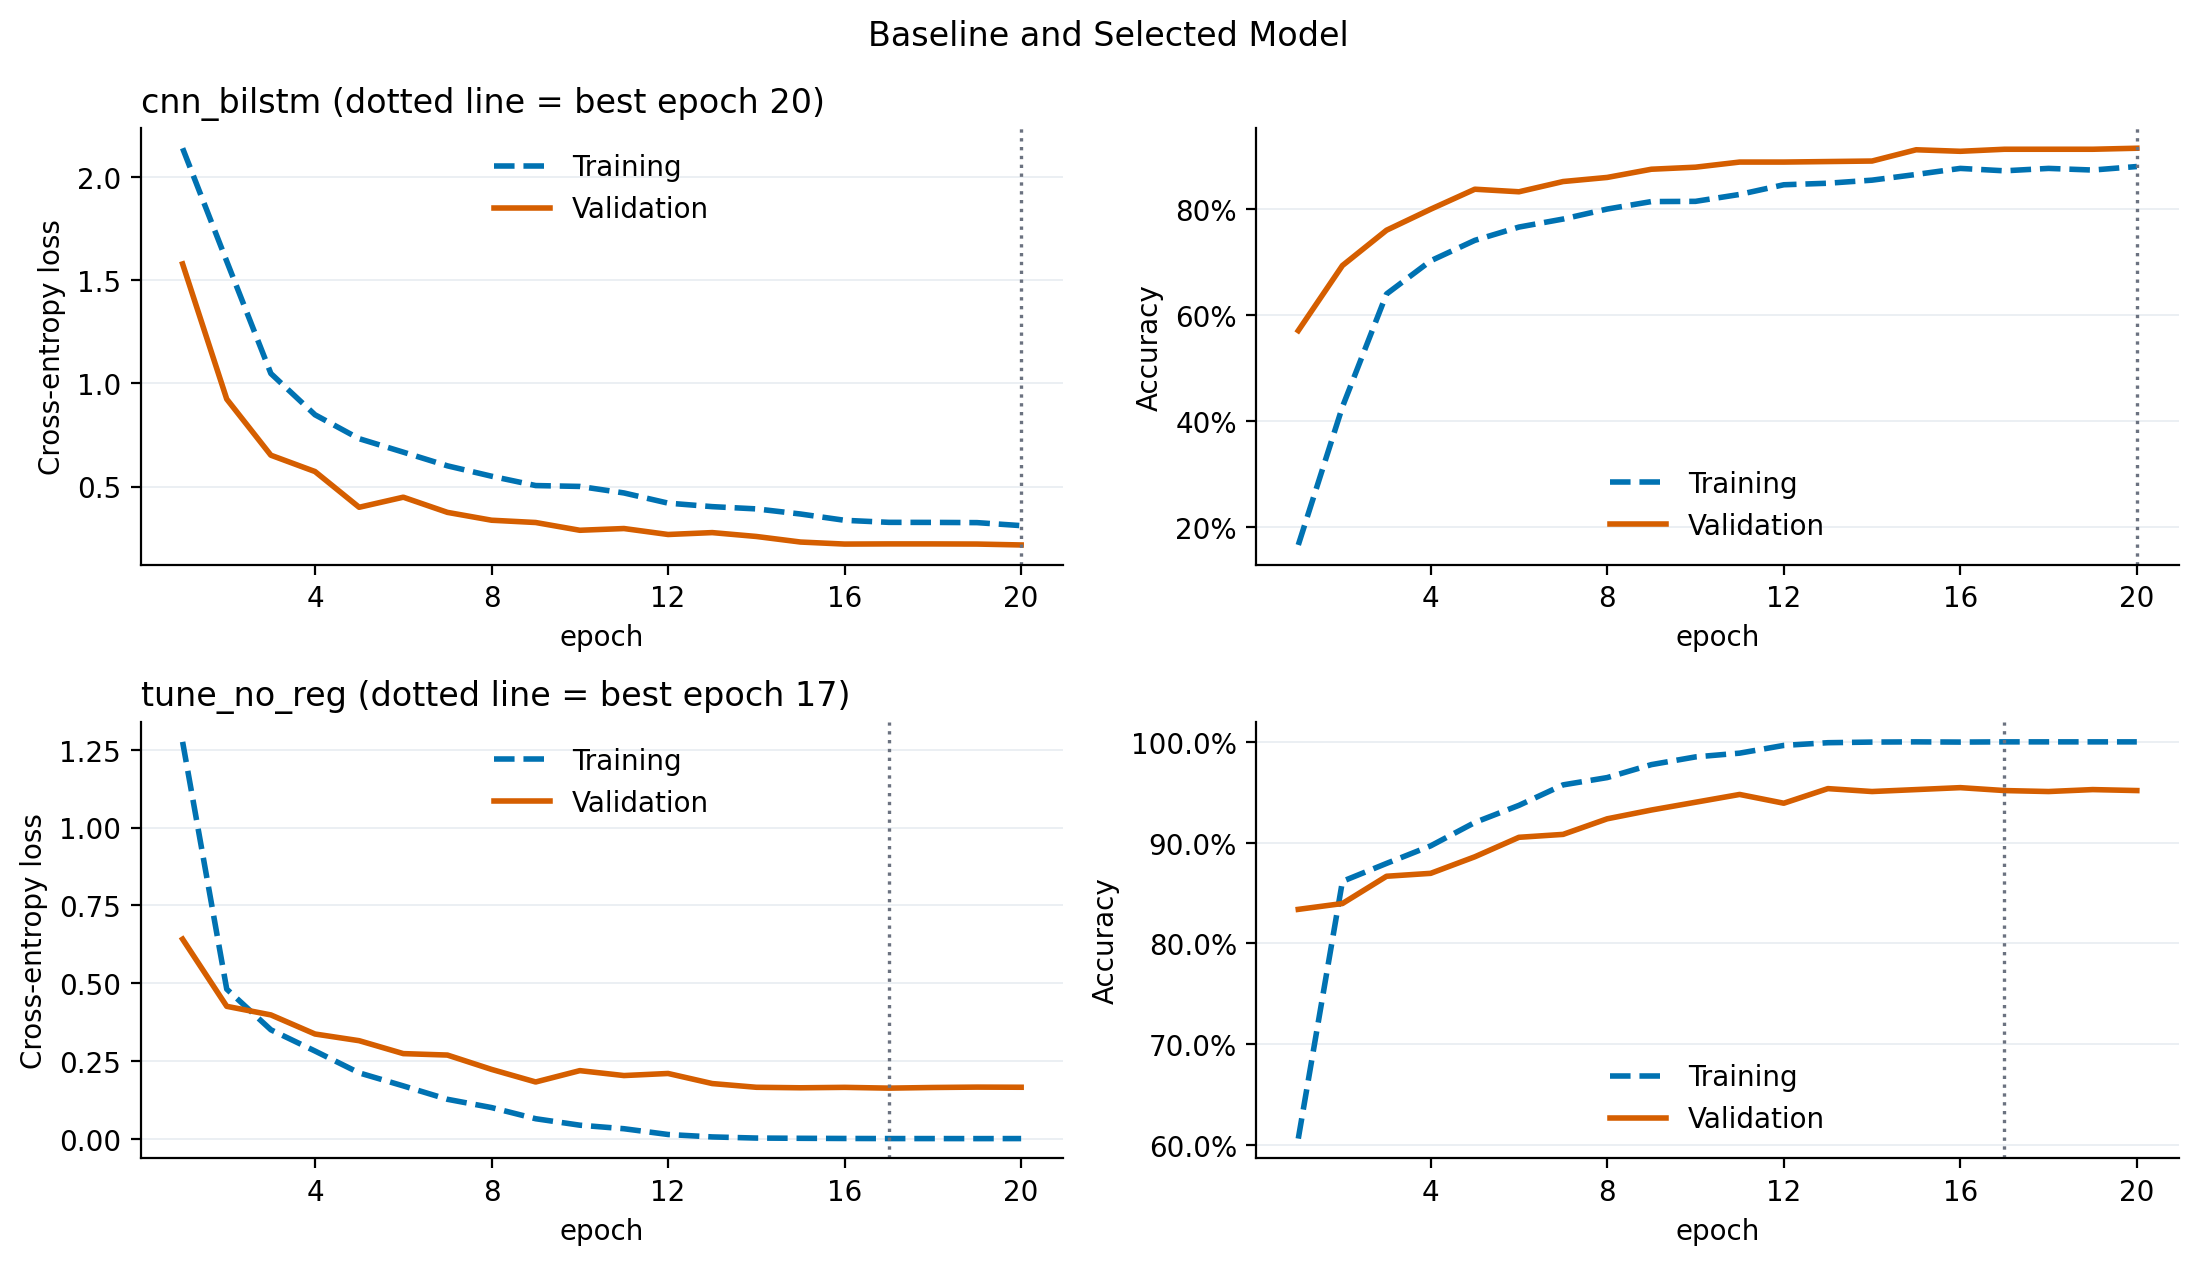

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
plot_history(runs["cnn_bilstm"], axes[0, 0], axes[0, 1])
plot_history(runs["tune_no_reg"], axes[1, 0], axes[1, 1])
fig.suptitle("Baseline and Selected Model")
plt.tight_layout()

### Tuning Results

- Baseline test accuracies were 82.61% for pixel LSTM, 87.63% for CNN, 89.86% for CNN with LSTM, and 92.17% for bidirectional recurrence.
- The configuration reached validation macro F1 of 0.9471, compared with 0.9040 for the baseline. Selection used validation scores throughout.
- Disabling augmentation alone produced validation macro F1 of 0.9342. Disabling augmentation, dropout, and weight decay together produced the highest validation score.
- The combined change does not isolate dropout or weight decay effects. Controlled runs are needed before attributing improvement to either.
- Increasing size or depth did not exceed the selected score. Unequal capacity and tuning coverage restrict claims about superiority.

## 11. Final Insights and Recommendations

- The validation-selected CNN with bidirectional LSTM classified 997 of 1,035 test images correctly, achieving 96.33% accuracy and 0.9602 macro F1. These estimates characterize the original split and seed. Conditional uncertainty intervals quantify sampling variation, while independent-image performance requires evaluation on photographs separated by object identity or acquisition source.
- Cat and dog discrimination should receive priority in subsequent experiments. Confusion between these classes produced 27 of 38 errors; their F1 scores were 0.8848 and 0.8421, respectively. Validation-based review should examine annotation ambiguity, occlusion, object scale and background composition before evaluating targeted sampling or resolution changes under a fixed protocol.
- Similarity screening identified 41 test images with average hashes also present in training or validation data. Candidate matches require visual confirmation because hash equality does not establish duplication. Confirmed image families should remain together during splitting. Performance on the remaining images is descriptive and cannot substitute for an independent holdout.
- The selected configuration disabled augmentation, dropout and weight decay while retaining batch normalization. Its validation macro F1 exceeded the baseline, but the combined ablation cannot identify individual contributions. Separate controlled experiments should vary these settings independently, with equal training budgets and repeated seeds used to estimate variability across fitted models.
- Model complexity should be assessed alongside classification performance. The selected model contains 1,503,208 parameters, versus 305,128 in the CNN baseline. Comparable tuning searches are needed before attributing gains to recurrence. Deployment comparisons should report inference latency, memory use and class-specific accuracy under the same hardware conditions and representative image distributions.
- Reproducibility requires retained split assignments, complete configurations, package version inventories, predictions and model checkpoints. Historical elapsed durations include unexplained intervals and do not measure active computation. Future studies should record computational conditions, freeze validation-based selection before test evaluation, and report uncertainty across seeds. Aspect-preserving resizing and acquisition-related shortcuts warrant prespecified validation comparisons.

## 12. Conclusion

The selected CNN-BiLSTM achieved 96.33% test accuracy and 0.9602 macro F1 on the original split. Cat-dog confusion was the principal error source. These results support the tested configuration, while broader generalization requires independent image groups, repeated seeds and controlled comparisons with simpler models.